# EDA — Anuran Calls (MFCCs)

Checking the dataset before building anything on top of it: shape, missing
values, class balance, feature ranges, and the `RecordID` group-leakage
issue flagged in `data/SOURCE.md`.

In [1]:
import pandas as pd

df = pd.read_csv("../data/Frogs_MFCCs.csv")
df.columns = [c.strip() for c in df.columns]
df.shape

(7195, 26)

In [2]:
df.isnull().sum().sum()  # expect 0

np.int64(0)

In [3]:
feature_cols = [c for c in df.columns if c.startswith("MFCCs_")]
len(feature_cols), feature_cols[:5]

(22, ['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5'])

## Class balance

Target is `Species`. `Family` and `Genus` are dropped — they're coarser versions of the same label.

In [4]:
df["Species"].value_counts()

Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68
Name: count, dtype: int64

Matplotlib is building the font cache; this may take a moment.


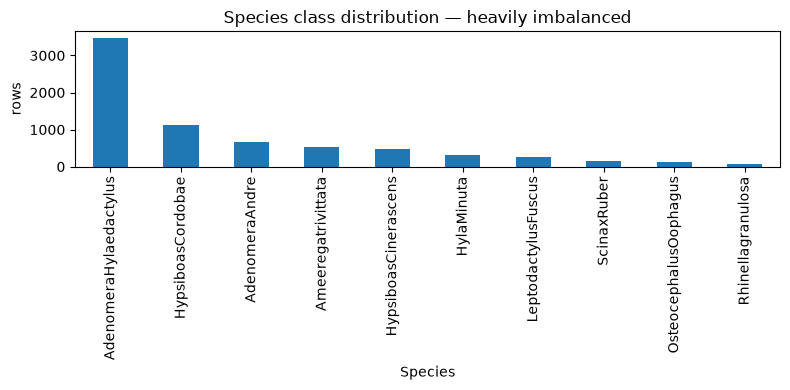

In [5]:
import matplotlib.pyplot as plt

counts = df["Species"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="bar", ax=ax)
ax.set_ylabel("rows")
ax.set_title("Species class distribution — heavily imbalanced")
plt.tight_layout()
plt.show()

Biggest class (`AdenomeraHylaedactylus`) outnumbers the smallest
(`Rhinellagranulosa`) by roughly 50x. Accuracy alone will look good just by
nailing the big classes — macro-averaged metrics and MCC matter here.

## Feature ranges

Checking whether scaling matters for the distance/gradient-based models (KNN, SVM, Logistic Regression).

In [6]:
df[feature_cols].describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
MFCCs_ 1,-0.251179,1.000000,0.989885,0.069016
MFCCs_ 2,-0.673025,1.000000,0.323584,0.218653
MFCCs_ 3,-0.436028,1.000000,0.311224,0.263527
MFCCs_ 4,-0.472676,1.000000,0.445997,0.160328
MFCCs_ 5,-0.636012,0.752246,0.127046,0.162722
MFCCs_ 6,-0.410417,0.964240,0.097939,0.120412
MFCCs_ 7,-0.538982,1.000000,-0.001397,0.171404
MFCCs_ 8,-0.576506,0.551762,-0.000370,0.116302
MFCCs_ 9,-0.587313,0.738033,0.128213,0.179008
MFCCs_10,-0.952266,0.522768,0.055998,0.127099


MFCCs are all roughly in the same [-1, 1] range already (they're
normalized coefficients by construction), so scaling won't change much here
— but it's still included in the pipelines for KNN/SVM/Logistic Regression
since it's good practice and costs nothing.

## Group leakage check

`RecordID` — how many distinct recordings, and how many syllables per recording?

In [7]:
df["RecordID"].nunique(), df.groupby("RecordID").size().describe()

(60,
 count     60.000000
 mean     119.916667
 std      138.866268
 min        1.000000
 25%       21.750000
 50%       53.000000
 75%      172.000000
 max      458.000000
 dtype: float64)

Only 60 recordings produced 7195 syllable rows — some recordings
contribute hundreds of near-identical syllables. A plain stratified
train/test split will scatter syllables from the same recording across both
sides, which inflates every model's reported score to some degree. This is
documented as a known limitation in the README rather than fixed with a
group-aware split, given the time budget for this assignment.

## Summary

- 7195 rows, 22 numeric MFCC features, no missing values — clean enough that
  no imputer is needed in the pipelines.
- 10-class target, heavily imbalanced — macro-averaged precision/recall/F1
  and MCC are the metrics that actually matter, not raw accuracy.
- Features are already on a comparable scale, but `StandardScaler` is kept
  in the pipelines for KNN, SVM, and Logistic Regression anyway.
- `RecordID` grouping causes mild train/test leakage under a plain
  stratified split — called out as a limitation, not silently ignored.